<a href="https://colab.research.google.com/github/2403a51078-code/AIDL_LAB_ASSIGNMENTS/blob/main/AIDL_lab18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 121MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 15.6MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 49.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.97MB/s]


Training samples: 60000
Testing samples: 10000


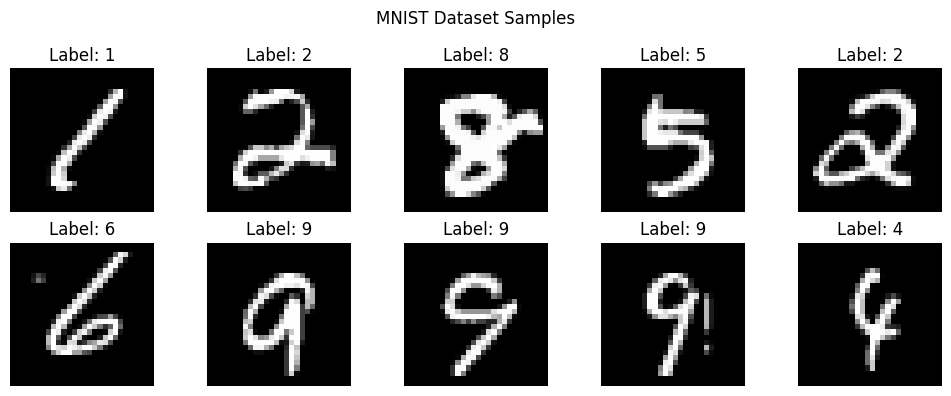


========== TRAINING VAE ==========
Epoch [1/10] Total Loss: 164.4531 | BCE: 148.6776 | KLD: 15.7756
Epoch [2/10] Total Loss: 120.9869 | BCE: 98.3554 | KLD: 22.6315
Epoch [3/10] Total Loss: 114.4353 | BCE: 90.3182 | KLD: 24.1171
Epoch [4/10] Total Loss: 111.5575 | BCE: 86.8914 | KLD: 24.6661
Epoch [5/10] Total Loss: 109.8013 | BCE: 84.8809 | KLD: 24.9204
Epoch [6/10] Total Loss: 108.6257 | BCE: 83.5577 | KLD: 25.0679
Epoch [7/10] Total Loss: 107.7513 | BCE: 82.5479 | KLD: 25.2034
Epoch [8/10] Total Loss: 107.1541 | BCE: 81.8320 | KLD: 25.3221
Epoch [9/10] Total Loss: 106.6317 | BCE: 81.2708 | KLD: 25.3609
Epoch [10/10] Total Loss: 106.1609 | BCE: 80.7582 | KLD: 25.4027


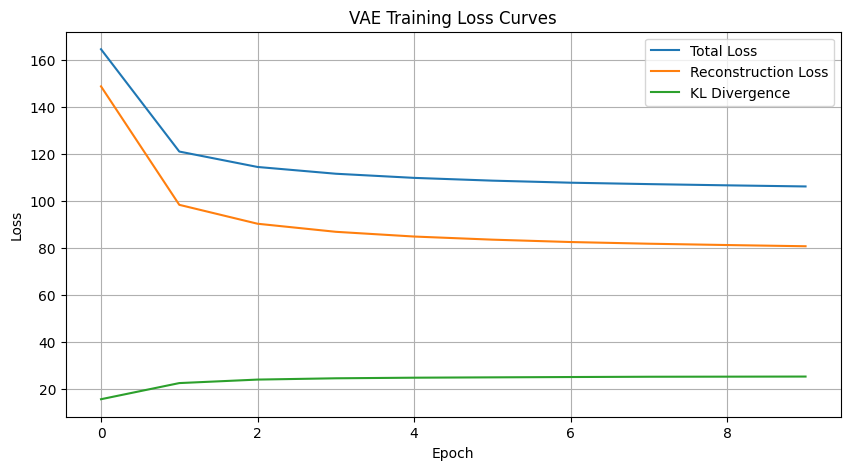


========== TRAINING BASELINE AUTOENCODER ==========
Epoch [1/10] Autoencoder Loss: 129.8424
Epoch [2/10] Autoencoder Loss: 82.8262
Epoch [3/10] Autoencoder Loss: 76.9945
Epoch [4/10] Autoencoder Loss: 74.1848
Epoch [5/10] Autoencoder Loss: 72.3774
Epoch [6/10] Autoencoder Loss: 71.1010
Epoch [7/10] Autoencoder Loss: 70.1162
Epoch [8/10] Autoencoder Loss: 69.3305
Epoch [9/10] Autoencoder Loss: 68.7121
Epoch [10/10] Autoencoder Loss: 68.1861


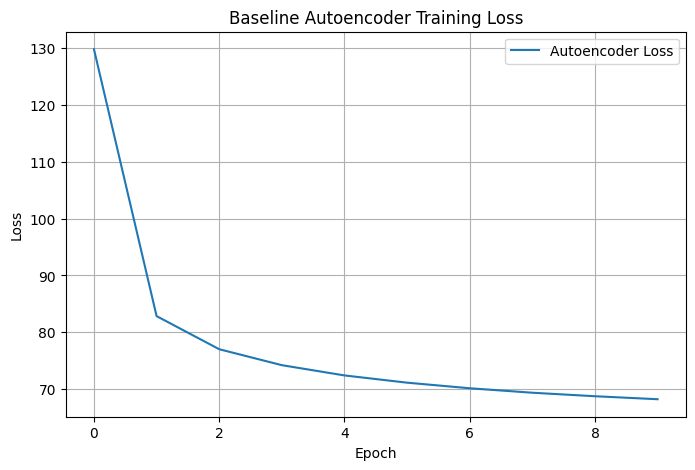


========== VAE PERFORMANCE ==========
Reconstruction BCE: 80.4162
KL Divergence: 25.1735
Reconstruction MSE: 0.013427

========== AUTOENCODER PERFORMANCE ==========
Reconstruction BCE: 67.9566
Reconstruction MSE: 0.008303


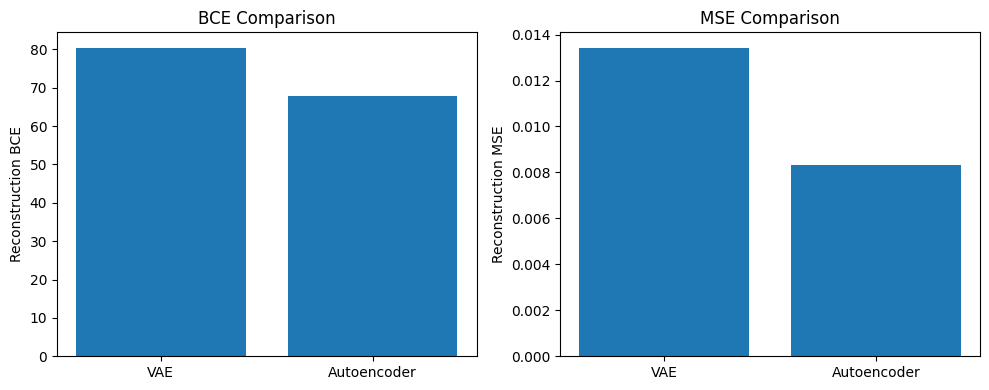

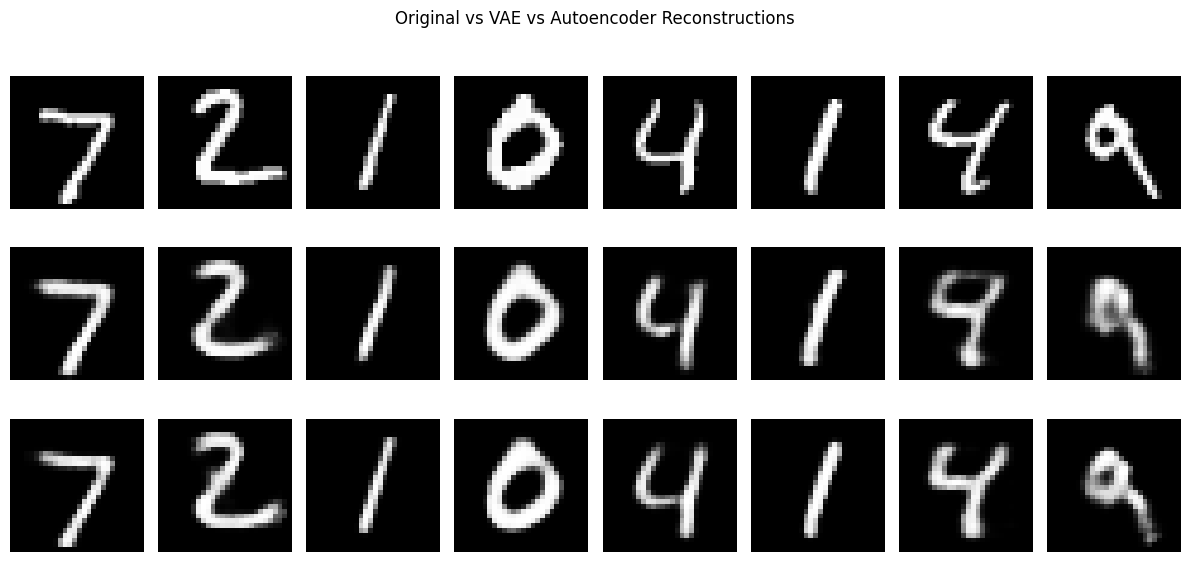

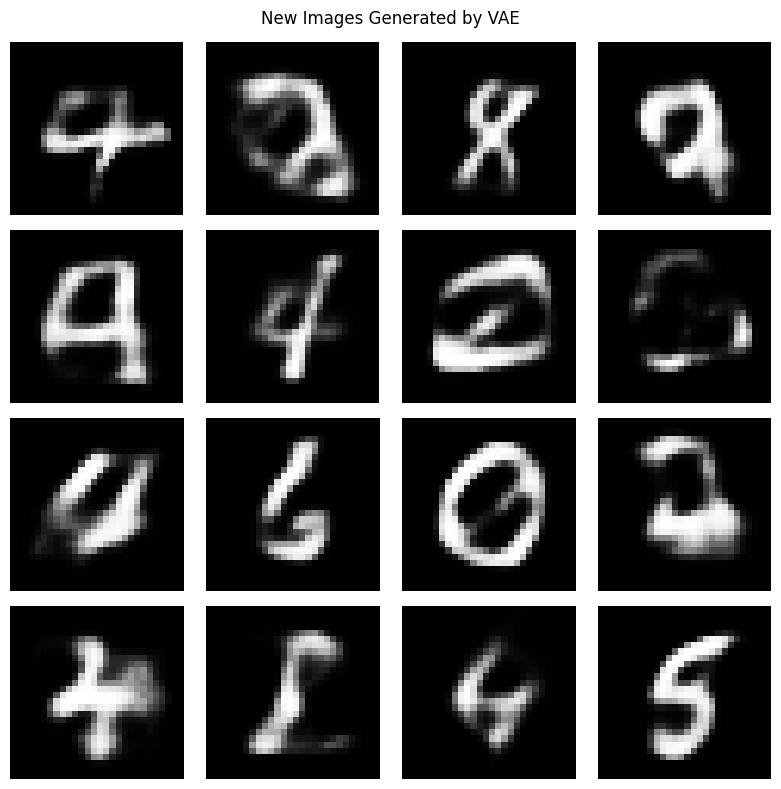


Models saved successfully!

========== FINAL RESULTS ==========

Variational Autoencoder:
BCE Loss: 80.4162
KL Divergence: 25.1735
MSE: 0.013427

Baseline Autoencoder:
BCE Loss: 67.9566
MSE: 0.008303

EXPERIMENT COMPLETED SUCCESSFULLY!


In [ ]:

# ==============================================================
# LAB EXPERIMENT 18
# IMPLEMENTING A SIMPLE VARIATIONAL AUTOENCODER (VAE)
# FOR IMAGE GENERATION USING MNIST DATASET
# ==============================================================

# STEP 1: IMPORT LIBRARIES

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import random

# Set random seed
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# STEP 2: SET HYPERPARAMETERS

BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 0.001

INPUT_DIM = 784
HIDDEN_DIM = 400
LATENT_DIM = 20

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# STEP 3: DOWNLOAD AND PREPROCESS MNIST DATASET

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))


# STEP 4: VISUALIZE MNIST DATASET

images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title("Label: " + str(labels[i].item()))
    plt.axis("off")

plt.suptitle("MNIST Dataset Samples")
plt.tight_layout()
plt.show()


# STEP 5: IMPLEMENT VARIATIONAL AUTOENCODER

class VAE(nn.Module):

    def __init__(self):
        super(VAE, self).__init__()

        # Encoder
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.fc_logvar = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        # Decoder
        self.fc3 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc4 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):

        h = F.relu(self.fc1(x))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    # Reparameterization trick
    def reparameterize(self, mu, logvar):

        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)

        z = mu + eps * std

        return z

    def decode(self, z):

        h = F.relu(self.fc3(z))

        return torch.sigmoid(self.fc4(h))

    def forward(self, x):

        x = x.view(-1, INPUT_DIM)

        mu, logvar = self.encode(x)

        z = self.reparameterize(mu, logvar)

        reconstruction = self.decode(z)

        return reconstruction, mu, logvar


# STEP 6: DEFINE VAE LOSS FUNCTION

def vae_loss(reconstruction, original, mu, logvar):

    original = original.view(-1, INPUT_DIM)

    # Reconstruction loss
    BCE = F.binary_cross_entropy(
        reconstruction,
        original,
        reduction="sum"
    )

    # KL Divergence
    KLD = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    # Total loss
    loss = BCE + KLD

    return loss, BCE, KLD


# STEP 7: INITIALIZE AND TRAIN VAE

vae = VAE().to(device)

optimizer = optim.Adam(
    vae.parameters(),
    lr=LEARNING_RATE
)

vae_losses = []
vae_bce_losses = []
vae_kld_losses = []

print("\n========== TRAINING VAE ==========")

for epoch in range(EPOCHS):

    vae.train()

    total_loss = 0
    total_bce = 0
    total_kld = 0

    for images, _ in train_loader:

        images = images.to(device)

        optimizer.zero_grad()

        reconstruction, mu, logvar = vae(images)

        loss, BCE, KLD = vae_loss(
            reconstruction,
            images,
            mu,
            logvar
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_bce += BCE.item()
        total_kld += KLD.item()

    n = len(train_dataset)

    avg_loss = total_loss / n
    avg_bce = total_bce / n
    avg_kld = total_kld / n

    vae_losses.append(avg_loss)
    vae_bce_losses.append(avg_bce)
    vae_kld_losses.append(avg_kld)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Total Loss: {avg_loss:.4f} | "
        f"BCE: {avg_bce:.4f} | "
        f"KLD: {avg_kld:.4f}"
    )


# STEP 8: PLOT VAE LOSS CURVES

plt.figure(figsize=(10, 5))

plt.plot(vae_losses, label="Total Loss")
plt.plot(vae_bce_losses, label="Reconstruction Loss")
plt.plot(vae_kld_losses, label="KL Divergence")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss Curves")

plt.legend()
plt.grid(True)
plt.show()


# STEP 9: IMPLEMENT BASELINE AUTOENCODER

class Autoencoder(nn.Module):

    def __init__(self):
        super(Autoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM)
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM),
            nn.Sigmoid()
        )

    def forward(self, x):

        x = x.view(-1, INPUT_DIM)

        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded


# STEP 10: TRAIN BASELINE AUTOENCODER

ae = Autoencoder().to(device)

ae_optimizer = optim.Adam(
    ae.parameters(),
    lr=LEARNING_RATE
)

ae_losses = []

print("\n========== TRAINING BASELINE AUTOENCODER ==========")

for epoch in range(EPOCHS):

    ae.train()

    total_loss = 0

    for images, _ in train_loader:

        images = images.to(device)

        ae_optimizer.zero_grad()

        reconstruction = ae(images)

        loss = F.binary_cross_entropy(
            reconstruction,
            images.view(-1, INPUT_DIM),
            reduction="sum"
        )

        loss.backward()
        ae_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_dataset)

    ae_losses.append(avg_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Autoencoder Loss: {avg_loss:.4f}"
    )


# STEP 11: PLOT AUTOENCODER LOSS

plt.figure(figsize=(8, 5))

plt.plot(ae_losses, label="Autoencoder Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline Autoencoder Training Loss")

plt.legend()
plt.grid(True)
plt.show()


# STEP 12: EVALUATE VAE

def evaluate_vae(model, loader):

    model.eval()

    total_bce = 0
    total_kld = 0
    total_mse = 0
    total_pixels = 0

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(device)

            reconstruction, mu, logvar = model(images)

            target = images.view(-1, INPUT_DIM)

            _, BCE, KLD = vae_loss(
                reconstruction,
                images,
                mu,
                logvar
            )

            MSE = F.mse_loss(
                reconstruction,
                target,
                reduction="sum"
            )

            total_bce += BCE.item()
            total_kld += KLD.item()
            total_mse += MSE.item()

            total_pixels += target.numel()

    n = len(loader.dataset)

    return (
        total_bce / n,
        total_kld / n,
        total_mse / total_pixels
    )


# STEP 13: EVALUATE BASELINE AUTOENCODER

def evaluate_ae(model, loader):

    model.eval()

    total_bce = 0
    total_mse = 0
    total_pixels = 0

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(device)

            reconstruction = model(images)

            target = images.view(-1, INPUT_DIM)

            BCE = F.binary_cross_entropy(
                reconstruction,
                target,
                reduction="sum"
            )

            MSE = F.mse_loss(
                reconstruction,
                target,
                reduction="sum"
            )

            total_bce += BCE.item()
            total_mse += MSE.item()

            total_pixels += target.numel()

    n = len(loader.dataset)

    return (
        total_bce / n,
        total_mse / total_pixels
    )


# STEP 14: CALCULATE PERFORMANCE METRICS

vae_bce, vae_kld, vae_mse = evaluate_vae(
    vae, test_loader
)

ae_bce, ae_mse = evaluate_ae(
    ae, test_loader
)

print("\n========== VAE PERFORMANCE ==========")

print("Reconstruction BCE:", round(vae_bce, 4))
print("KL Divergence:", round(vae_kld, 4))
print("Reconstruction MSE:", round(vae_mse, 6))

print("\n========== AUTOENCODER PERFORMANCE ==========")

print("Reconstruction BCE:", round(ae_bce, 4))
print("Reconstruction MSE:", round(ae_mse, 6))


# STEP 15: COMPARE BOTH MODELS

models = ["VAE", "Autoencoder"]

bce_values = [vae_bce, ae_bce]
mse_values = [vae_mse, ae_mse]

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(models, bce_values)
plt.title("BCE Comparison")
plt.ylabel("Reconstruction BCE")

plt.subplot(1, 2, 2)
plt.bar(models, mse_values)
plt.title("MSE Comparison")
plt.ylabel("Reconstruction MSE")

plt.tight_layout()
plt.show()


# STEP 16: VISUALIZE ORIGINAL AND RECONSTRUCTED IMAGES

vae.eval()
ae.eval()

images, labels = next(iter(test_loader))

images = images[:8].to(device)

with torch.no_grad():

    vae_reconstruction, _, _ = vae(images)

    ae_reconstruction = ae(images)

original = images.cpu().view(-1, 28, 28)

vae_output = vae_reconstruction.cpu().view(-1, 28, 28)

ae_output = ae_reconstruction.cpu().view(-1, 28, 28)

plt.figure(figsize=(12, 6))

for i in range(8):

    # Original
    plt.subplot(3, 8, i + 1)
    plt.imshow(original[i], cmap="gray")
    plt.axis("off")

    # VAE Reconstruction
    plt.subplot(3, 8, i + 9)
    plt.imshow(vae_output[i], cmap="gray")
    plt.axis("off")

    # AE Reconstruction
    plt.subplot(3, 8, i + 17)
    plt.imshow(ae_output[i], cmap="gray")
    plt.axis("off")

plt.suptitle(
    "Original vs VAE vs Autoencoder Reconstructions"
)

plt.tight_layout()
plt.show()


# STEP 17: GENERATE NEW IMAGES USING VAE

vae.eval()

with torch.no_grad():

    z = torch.randn(
        16,
        LATENT_DIM
    ).to(device)

    generated_images = vae.decode(z)

plt.figure(figsize=(8, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    image = generated_images[i].cpu().view(28, 28)

    plt.imshow(image, cmap="gray")
    plt.axis("off")

plt.suptitle("New Images Generated by VAE")

plt.tight_layout()
plt.show()


# STEP 18: SAVE TRAINED MODELS

torch.save(
    vae.state_dict(),
    "mnist_vae.pth"
)

torch.save(
    ae.state_dict(),
    "mnist_autoencoder.pth"
)

print("\nModels saved successfully!")


# STEP 19: DISPLAY FINAL RESULTS

print("\n========== FINAL RESULTS ==========")

print("\nVariational Autoencoder:")
print("BCE Loss:", round(vae_bce, 4))
print("KL Divergence:", round(vae_kld, 4))
print("MSE:", round(vae_mse, 6))

print("\nBaseline Autoencoder:")
print("BCE Loss:", round(ae_bce, 4))
print("MSE:", round(ae_mse, 6))

print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")
